In [1]:
pip install matplotlib seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
#Load the cleaned data
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("telco_cleaned.csv")
num_cols = ["tenure", "monthlycharges", "totalcharges"]
df.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Summarising statistics (mean, median, mode)
print("Mean:\n", df[num_cols].mean(), "\n")
print("Median:\n", df[num_cols].median(), "\n")
print("Mode:\n", df[num_cols].mode().iloc[0], "\n")
df[num_cols].describe()

Mean:
 tenure              32.371149
monthlycharges      64.761692
totalcharges      2279.734304
dtype: float64 

Median:
 tenure              29.00
monthlycharges      70.35
totalcharges      1394.55
dtype: float64 

Mode:
 tenure             1.00
monthlycharges    20.05
totalcharges       0.00
Name: 0, dtype: float64 



,tenure,monthlycharges,totalcharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


### Findings: Summary Statistics

- The dataset has **7,043 customers** and no missing values in the numerical columns.
- **Tenure:** Average is 32.4 months, median is 29 months. The most common value (mode) is **1 month**, so many customers are brand new.
- **Monthly Charges:** Average is 64.76, median is 70.35, and they range from 18.25 to 118.75. The mode is **20.05**, which points to a large group on low-cost basic plans.
- **Total Charges:** The mean (2,279.73) is much higher than the median (1,394.55), so the data is **right-skewed**: most customers have small totals and a few have very large ones. The mode is **0**, from the 11 new customers (tenure 0) that I filled with 0 during cleaning.

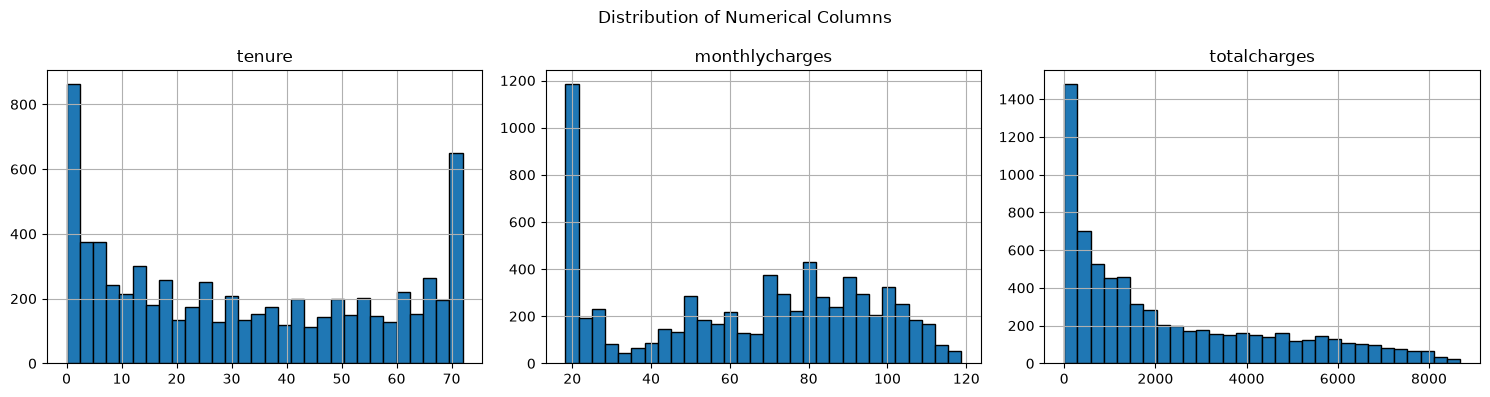

In [4]:
# Histograms
df[num_cols].hist(bins=30, figsize=(15, 4), layout=(1, 3), edgecolor="black")
plt.suptitle("Distribution of Numerical Columns")
plt.tight_layout()
plt.show()

### Findings: Histograms

- **Tenure:** There are two clear peaks, one at **0–2 months** (about 850 new customers) and one at **70–72 months** (about 650 long-term customers). The company has many new customers and many loyal ones, with fewer in between.
- **Monthly Charges:** There's a tall spike around **20** (about 1,200 customers on basic plans), and another cluster between **70 and 100** (customers on premium plans such as fiber internet).
- **Total Charges:** Highly **right-skewed**. Most customers have total charges below 1,000, and the count drops steadily as charges increase.

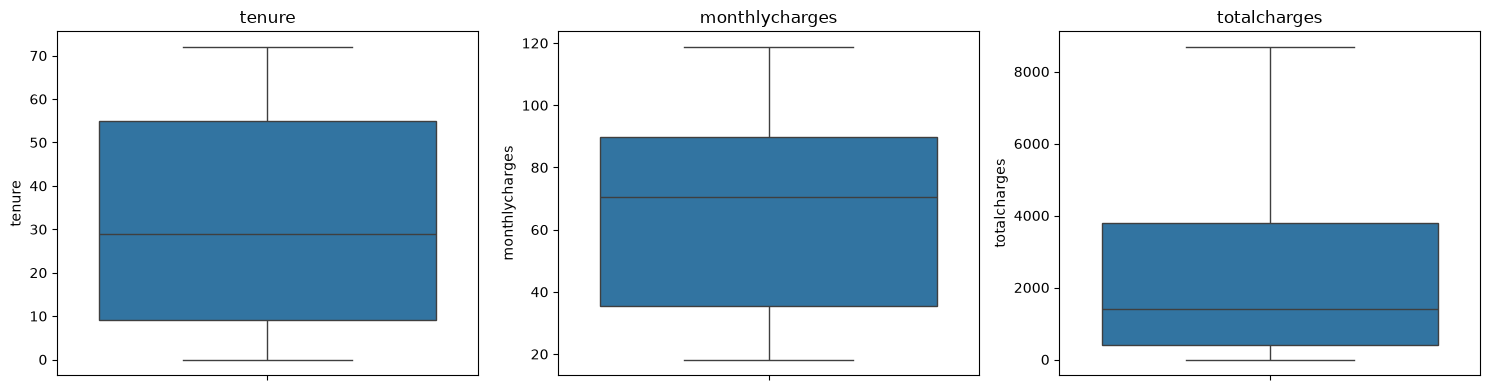

In [5]:
#Box Plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Findings: Box Plots

- **No outliers** appear in any of the three columns, so no values need to be removed.
- **Tenure:** The middle 50% of customers have been with the company for 9 to 55 months (median 29).
- **Monthly Charges:** The middle 50% pay between 35.50 and 89.85 (median 70.35).
- **Total Charges:** The middle 50% fall between 398.55 and 3,786.60. The median line sits close to the bottom of the box and the upper whisker is long, which confirms the right skew seen in the histogram.

churn
No     5174
Yes    1869
Name: count, dtype: int64
churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


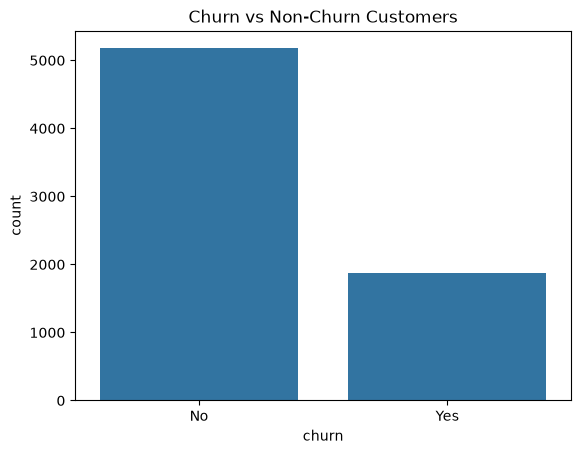

In [6]:
#Churn vs non-churn proportions

print(df["churn"].value_counts())
print((df["churn"].value_counts(normalize=True) * 100).round(2))

sns.countplot(x="churn", data=df)
plt.title("Churn vs Non-Churn Customers")
plt.show()

### Findings: Churn Proportion

- **5,174 customers (73.46%)** stayed with the company.
- **1,869 customers (26.54%)** churned (left the company).
- About **1 in every 4 customers** is leaving, which is a significant loss for a telecom business.
- The data is **imbalanced** (about 3:1), which is worth remembering if a prediction model is built later.

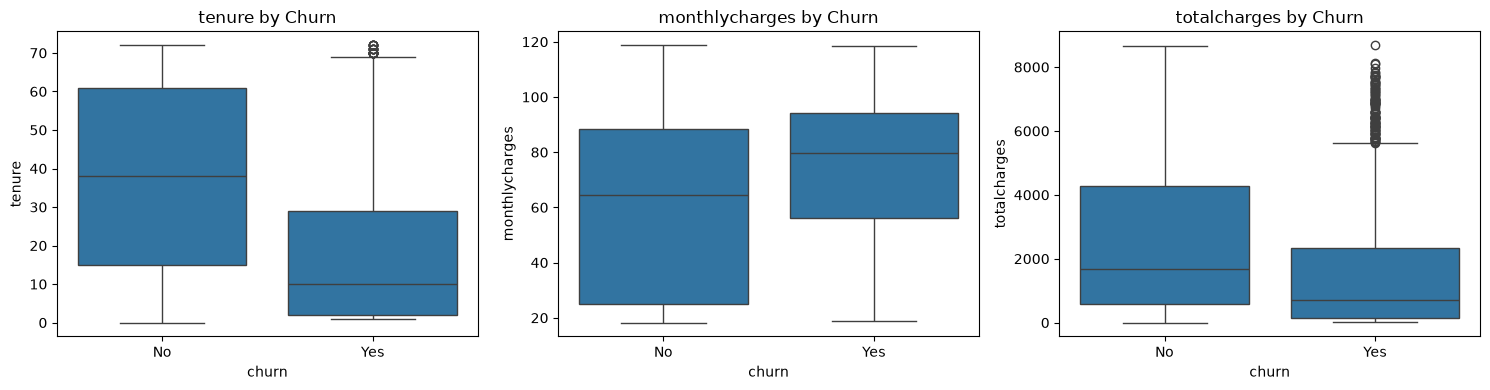

In [7]:
#Trend of numerical columns by churn status
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x="churn", y=col, data=df, ax=ax)
    ax.set_title(f"{col} by Churn")
plt.tight_layout()
plt.show()

### Observations: Numerical Columns by Churn

- **Tenure:** Customers who churned have a much lower tenure (median ≈ 10 months) than customers who stayed (median ≈ 38 months). Most churn happens in the first year.
- **Monthly Charges:** Churned customers pay higher monthly charges (median ≈ 80) than retained customers (median ≈ 65). Higher bills may push customers to leave.
- **Total Charges:** Churned customers have lower total charges (median ≈ 700). That's mainly because they left early and didn't build up a long bill. The outliers show that some long-time, high-value customers also churned.

**Key insight:** New customers with high monthly charges are the most at risk of churning. Focusing retention efforts (discounts, onboarding support) on the first 12 months could reduce churn.

In [8]:
df.groupby("churn")[num_cols].median()

,tenure,monthlycharges,totalcharges
churn,,,
No,38.0,64.425,1679.525
Yes,10.0,79.650,703.550


### Findings: Median Values by Churn

| | Tenure | Monthly Charges | Total Charges |
|---|---|---|---|
| Stayed (No) | 38 months | 64.43 | 1,679.53 |
| Churned (Yes) | 10 months | 79.65 | 703.55 |

- Churned customers left after a median of only **10 months**, compared with 38 months for loyal customers.
- Churned customers paid about **15 more per month**.
- Their total charges are lower because they left early.

**Exact medians confirm the box plots: churned customers stayed only 10 months vs 38, and paid 79.65/month vs 64.43**

## Task 3 Summary

- 26.54% of customers churned, so about 1 in 4 customers is lost.
- Churn is highest among **new customers**: the median tenure of churned customers is just 10 months.
- Customers with **higher monthly charges** are more likely to leave.
- Total charges are right-skewed, and there are no outliers in the numerical data.
- **Recommendation:** Focus retention efforts on customers in their first year and on those paying high monthly charges, for example with loyalty discounts, better onboarding, or plan reviews.